## **Практическая работа №2**

Вариант 7

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Вариант 7
t = np.arange(1, 11)

y = np.array([ 134, 130, 128, 126, 122, 120, 117, 112, 108, 105 ])

data = pd.DataFrame({
    't': t,
    'y': y
})

data

,t,y
0,1,134
1,2,130
2,3,128
3,4,126
4,5,122
5,6,120
6,7,117
7,8,112
8,9,108
9,10,105


### **Метод простой скользящей средней**

Для нескольких соседних уровней вычисляется среднее арифметическое, которое относится к середине интервала; затем интервал сдвигается на один уровень вправо.

Интервал должен состоять из нечётного числа уровней

Используем интервал из трёх значений:

$$ \bar y_t = \frac{y_{t-1}+y_t+y_{t+1}}{3} $$

То есть каждый раз будем брать 3 соседних числа.

In [2]:
# Простая скользящая средняя с интервалом m = 3
y_smooth = []

for i in range(1, len(y) - 1):
    value = (y[i - 1] + y[i] + y[i + 1]) / 3
    y_smooth.append(value)

y_smooth = np.array(y_smooth)

# Сглаженные значения соответствуют периодам t = 2 ... 9
t_smooth = np.arange(2, 10)

smooth_data = pd.DataFrame({
    't': t_smooth,
    'Сглаженное значение': y_smooth
})

smooth_data

,t,Сглаженное значение
0,2,130.666667
1,3,128.000000
2,4,125.333333
3,5,122.666667
4,6,119.666667
5,7,116.333333
6,8,112.333333
7,9,108.333333


При простой скользящей средней крайние уровни ряда теряются, то есть не сглаживаются

График исходных и сглаженных данных

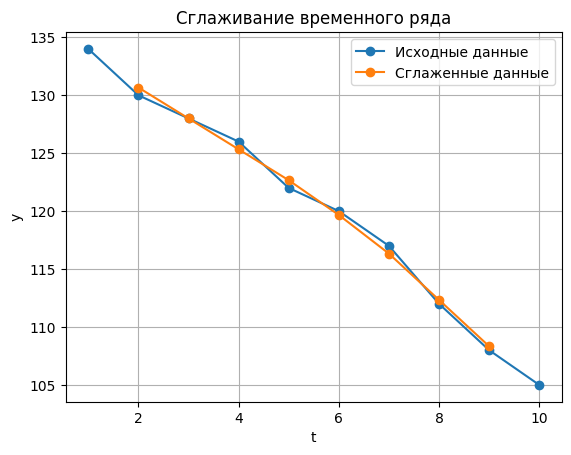

In [3]:
plt.plot(t, y, marker='o', label='Исходные данные')
plt.plot(t_smooth, y_smooth, marker='o', label='Сглаженные данные')

plt.xlabel('t')
plt.ylabel('y')
plt.title('Сглаживание временного ряда')
plt.grid()
plt.legend()
plt.show()

На графике видно, что ряд имеет практически линейную убывающую тенденцию.

### **Прогноз на t = 11**

Так как первые приросты примерно одинаковы, используем полином первого порядка (прямая).

Строим линейный тренд по сглаженным данным:

$$  y=at+b $$

In [4]:
# Строим линейный тренд по сглаженным данным
a, b = np.polyfit(t_smooth, y_smooth, 1) #построй полином первого порядка

print('a =', a)
print('b =', b)

# Прогноз для t = 11
t_forecast = 11
y_forecast = a * t_forecast + b

print('Прогноз на t = 11:', round(y_forecast, 2))

a = -3.150793650793651
b = 137.7460317460318
Прогноз на t = 11: 103.09


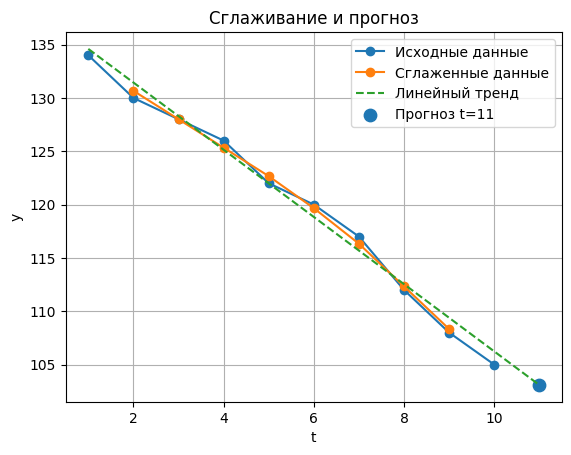

In [5]:
trend_t = np.arange(1, 12)
trend_y = a * trend_t + b

plt.plot(t, y, marker='o', label='Исходные данные')
plt.plot(t_smooth, y_smooth, marker='o', label='Сглаженные данные')
plt.plot(trend_t, trend_y, '--', label='Линейный тренд')
plt.scatter(11, y_forecast, s=80, label='Прогноз t=11')

plt.xlabel('t')
plt.ylabel('y')
plt.title('Сглаживание и прогноз')
plt.grid()
plt.legend()
plt.show()

Для варианта 7 было выполнено сглаживание временного ряда методом простой скользящей средней с интервалом m = 3. После сглаживания видно, что значения имеют примерно линейную убывающую тенденцию. Для прогноза был построен линейный тренд. Прогнозное значение на период t = 11 составляет 103,09.